In [1]:

import glob
from joblib import Parallel, delayed
#from catalog_plotter import plot_var, get_array
import numpy as np
import plotter_config as pc
import sim_name_remap as map
import netCDF4 as nc4
import os
import datetime as dt
from scipy.interpolate import interp1d
import pickle as pkl
import matplotlib.tri as tri
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import datetime
from astropy.time import Time
import utils


In [2]:

def get_simfield(sim, vars, date, t, plot_lev):

    sim_file = glob.glob(map.remap[sim] + date + '*')

    if len(sim_file) > 1: print('ERROR!!!!! More than one file detected with these specs')
    
    # Crack open the first file and read the convective top information, then loop over the rest
    sim_nc = nc4.Dataset(sim_file[0])
    simlon = sim_nc.variables['lon'][:]
    simlat = sim_nc.variables['lat'][:]
    hyam = sim_nc.variables['hyam'][:]
    hybm = sim_nc.variables['hybm'][:]
    date = sim_nc.variables['date'][t]
    datesec = sim_nc.variables['datesec'][t]
    simfield = np.squeeze(sim_nc.variables[vars[0]][t,:])  # Maybe this will account for the fact that some plot fields have 3D and others have 4D?
    if len(vars) > 1: 
        for v in range(len(vars)-1):
            curr_simfield = np.squeeze(sim_nc.variables[vars[v+1]][t,:])
            simfield = simfield + curr_simfield

    datestr = str(date) + '_' + str(int(datesec/3600.)).zfill(2) + 'Z'#_' + str(int((datesec/60.) % 60)).zfill(2) + 'min'    
    
    print('Simulated field shape = ', np.shape(simfield))

    return simfield, simlon, simlat, hyam, hybm, datestr

# This subroutine will interpolate an unstructured variable field (dimensions of lev x pt) to a specific pressure level 
# with help from the model pressure field (dimension of lev x pt, units of Pa)

def interp_to_prslev(var_arr, PS_arr, lon, lat, hyam, hybm, plot_lev):

    #print('Interpolating ' + var_name + ' to the ' + str(plot_lev) + 'hPa surface at ' + valid_datestr)

    if len(np.shape(var_arr)) == 3: 
    
        var_plev = np.zeros((len(lat), len(lon)))-999
    
        for ln in range(len(lon)):
            for lt in range(len(lat)):
    
                curr_PS = PS_arr[lt,ln]
                curr_plev = (hyam*1.0e5 + hybm*curr_PS)/100.  
    
                plev_f = interp1d(curr_plev, np.squeeze(var_arr[:,lt,ln]), bounds_error=False, fill_value=-999)
    
                var_plev[lt,ln] = plev_f(plot_lev)

    elif len(np.shape(var_arr)) == 2: var_plev = var_arr
    
    return var_plev

def moving_window_smooth(data, width=1):
    data_copy = np.copy(data)
    smoothed = np.zeros(data_copy.shape)
    for ix in range(data_copy.shape[0]):
        for iy in range(data_copy.shape[1]):
            smoothed[ix,iy] = np.nanmean(data_copy[ix-width:ix+width,iy-width:iy+width])
    return smoothed    

def draw_box(ax, left, right, bot, top, col, thk):
    ax.plot([left, left], [bot, top], color=col, linewidth=thk)
    ax.plot([right, right], [bot, top], color=col, linewidth=thk)
    ax.plot([left, right], [bot, bot], color=col, linewidth=thk)
    ax.plot([left, right], [top, top], color=col, linewidth=thk) 
    

In [3]:

def get_ACCLIP_merge_data(OBSROOT, FLT_DATES, var_str):
    
    OBSvar = []

    for FLT_DATE in FLT_DATES:
    
        AIRFILE = glob.glob(OBSROOT + '*' + FLT_DATE + '*.ict')[0]     
        AIRheaders = np.loadtxt(AIRFILE, delimiter=',', usecols = (0), dtype='str')
        AIRdata = np.loadtxt(AIRFILE, delimiter=',', skiprows=int(AIRheaders[0]))  # Read the file
        OBSvar.extend(AIRdata[:,int(list(AIRheaders).index(var_str))-11])
        
    return np.asarray(OBSvar)
    
def plot_map(ax, lon, lat, var_plot, var_name, plot_lev, sim, extent, conv_dom, datestr, cb=0, let=''):

    GV_OBSROOT = '/glade/work/wsmith/ACCLIP_GV_R1_60SEC_Merge/'
    GV_FLT_DATES = ['20220819']
    ACCLIP_GV_lon = get_ACCLIP_merge_data(GV_OBSROOT, GV_FLT_DATES, 'GGLON') 
    ACCLIP_GV_lat = get_ACCLIP_merge_data(GV_OBSROOT, GV_FLT_DATES, 'GGLAT')     

    WB_OBSROOT = '/glade/work/wsmith/ACCLIP_WB57_R1_60SEC_Merge/'
    WB_FLT_DATES = ['20220819']
    ACCLIP_WB_lon = get_ACCLIP_merge_data(WB_OBSROOT, WB_FLT_DATES, 'G_LONG_MMS') 
    ACCLIP_WB_lat = get_ACCLIP_merge_data(WB_OBSROOT, WB_FLT_DATES, 'G_LAT_MMS') 
    
    ax.set_extent(extent)

    ax.coastlines()
    if plot_lev == 0: ax.set_title(let + sim + ' ' + var_name + ' on ' + datestr)
    else: ax.set_title(let + sim + ' ' + var_name + ' at ' + str(plot_lev) + 'hPa on ' + datestr)
    #ax.set_title(sim)
    
    cbar_lev, cbar_rgb, norm = utils.get_colorbar(var_name, plot_lev, cb)  # 0 standard, 1 weird, 2 reds

    print(np.min(var_plot), np.max(var_plot))

    cf = ax.contourf(lon, lat, var_plot, levels=cbar_lev, norm=norm, cmap=cbar_rgb, extend='both')

    ax.scatter(ACCLIP_GV_lon, ACCLIP_GV_lat, s=0.5, color='k')
    ax.scatter(ACCLIP_WB_lon, ACCLIP_WB_lat, s=0.5, color='k') 

    # Put a cross at the location where var_plot is maximized on the plot

    # Smooth first
    #var_plot_sm = moving_window_smooth(var_plot, width=1)
    
    i = np.where((lon >= conv_dom[0]) & (lon <= conv_dom[1]))[0]
    j = np.where((lat >= conv_dom[2]) & (lat <= conv_dom[3]))[0]
    var_sub = var_plot[np.ix_(j,i)]
    jj,ii = np.unravel_index(var_sub.argmax(), var_sub.shape)
    varmax_lonind = i[ii]
    varmax_latind = j[jj]
    
    #ax.scatter([lon[varmax_lonind]], [lat[varmax_latind]], marker='+', color='blue', s=50)

    draw_box(ax, conv_dom[0], conv_dom[1], conv_dom[2], conv_dom[3], [0.5,0.5,0.5], 1)

    return cf, varmax_lonind, varmax_latind, var_plot[varmax_latind,varmax_lonind], cbar_lev

def plot_prof(ax, varprof, PS, varstr, sim, SAVEFILE, xlim=[0,400]):

    plev = (hyam*1.0e5 + hybm*PS)/100. 

    ax.plot(varprof, plev)
    ax.set_xlim(xlim)
    ax.set_ylim(1000,50)
    ax.set_yscale('log')
    ax.set_xlabel(varstr + '(' + pc.var_info[varstr]['unit'] + ')')
    ax.set_ylabel('Pressure (hPa)')
    ax.set_title(sim)

    with open(SAVEFILE, 'wb') as f:
        pkl.dump((varprof, plev), f)


In [4]:

# Plot Q, CAPE, and ZMMU

# Top left, top right, middle left, middle right, lower left, lower right
#sims = ['2022_ERA5_ZM_30m','2022_MERRA2_ZM_30m','2022_ERA5_ZM_30m','2022_MERRA2_ZM_30m','2022_ERA5_ZM_30m','2022_MERRA2_ZM_30m']
sims = ['2022_E5-strong','2022_M2-strong','2022_E5-strong','2022_M2-strong','2022_E5-strong','2022_M2-strong']
#sims = ['2022_E5-1hr','2022_E5-3hr','2022_E5-1hr','2022_E5-3hr','2022_E5-1hr','2022_E5-3hr']
dates = ['2022-08-18','2022-08-18','2022-08-18','2022-08-18','2022-08-18','2022-08-18']
#ts = [0,0,0,0,0,0]
ts = [3,3,3,3,3,3]
#ts = [4,4,4,4,4,4]
vars = ['q','q','CAPE','CAPE','ZMMU','ZMMU']
#vars = ['q','q','ISOP','ISOP','ZMMU','ZMMU']
plot_levs = [850.,850.,0.,0.,250.,250.]
#plot_levs = [850., 850., 850., 850., 250., 250.]
cb=2

# Plot CO at various times

###sims = ['2022_E5-strong','2022_FreeRun','2022_E5-strong','2022_FreeRun','2022_E5-strong','2022_FreeRun']
##sims = ['2022_E5-strong','2022_M2-strong','2022_E5-strong','2022_M2-strong','2022_E5-strong','2022_M2-strong']
###sims = ['2022_E5-strong','2022_E5-weak','2022_E5-strong','2022_E5-weak','2022_E5-strong','2022_E5-weak']
##dates = ['2022-08-18','2022-08-18','2022-08-18','2022-08-18','2022-08-19','2022-08-19']
##ts = [0,0,4,4,0,0]
##vars = ['CO','CO','CO','CO','CO','CO']
##plot_levs = [150,150,150,150,150,150]
###plot_levs = [200,200,200,200,200,200]
##cb=0

#extent = [30,160,0,40]  # Anticylone box
#extent = [110,160,25,55]
extent = [105,145,25,45]  # August 19 box, full map boundaries
conv_dom = [110,122,36,42]   # Tiny box over the uplift region
#conv_dom = [105,145,25,45]   # The same as extent intentionally, to find max CO 
#conv_dom = [122,127,32,39]    # The Yellow Sea observation region

SAVEDIR = '/glade/u/home/wsmith/NudgeComparison_scripts/vars/'


In [5]:

# Read the model variables
simvar0, simlon, simlat, hyam, hybm, datestr0 = get_simfield(sims[0], pc.var_info[vars[0]]['vars'], dates[0], ts[0], plot_levs[0])
simPS0, simlon, simlat, hyam, hybm, datestr0 = get_simfield(sims[0], ['PS'], dates[0], ts[0], plot_levs[0])

simvar1, simlon, simlat, hyam, hybm, datestr1 = get_simfield(sims[1], pc.var_info[vars[1]]['vars'], dates[1], ts[1], plot_levs[1])
simPS1, simlon, simlat, hyam, hybm, datestr1 = get_simfield(sims[1], ['PS'], dates[1], ts[1], plot_levs[1])

simvar2, simlon, simlat, hyam, hybm, datestr2 = get_simfield(sims[2], pc.var_info[vars[2]]['vars'], dates[2], ts[2], plot_levs[2])
simPS2, simlon, simlat, hyam, hybm, datestr2 = get_simfield(sims[2], ['PS'], dates[2], ts[2], plot_levs[2])

simvar3, simlon, simlat, hyam, hybm, datestr3 = get_simfield(sims[3], pc.var_info[vars[3]]['vars'], dates[3], ts[3], plot_levs[3])
simPS3, simlon, simlat, hyam, hybm, datestr3 = get_simfield(sims[3], ['PS'], dates[3], ts[3], plot_levs[3])

simvar4, simlon, simlat, hyam, hybm, datestr4 = get_simfield(sims[4], pc.var_info[vars[4]]['vars'], dates[4], ts[4], plot_levs[4])
simPS4, simlon, simlat, hyam, hybm, datestr4 = get_simfield(sims[4], ['PS'], dates[4], ts[4], plot_levs[4])

simvar5, simlon, simlat, hyam, hybm, datestr5 = get_simfield(sims[5], pc.var_info[vars[5]]['vars'], dates[5], ts[5], plot_levs[5])
simPS5, simlon, simlat, hyam, hybm, datestr5 = get_simfield(sims[5], ['PS'], dates[5], ts[5], plot_levs[5])


Simulated field shape =  (32, 192, 288)
Simulated field shape =  (192, 288)
Simulated field shape =  (32, 192, 288)
Simulated field shape =  (192, 288)
Simulated field shape =  (192, 288)
Simulated field shape =  (192, 288)
Simulated field shape =  (192, 288)
Simulated field shape =  (192, 288)
Simulated field shape =  (32, 192, 288)
Simulated field shape =  (192, 288)
Simulated field shape =  (32, 192, 288)
Simulated field shape =  (192, 288)


-999000.0 19.686012404801453
-999000.0 19.22598153455635
0.0 1064.849
0.0 1128.6544
0.0 257.2792394506818
0.0 280.8287360245342


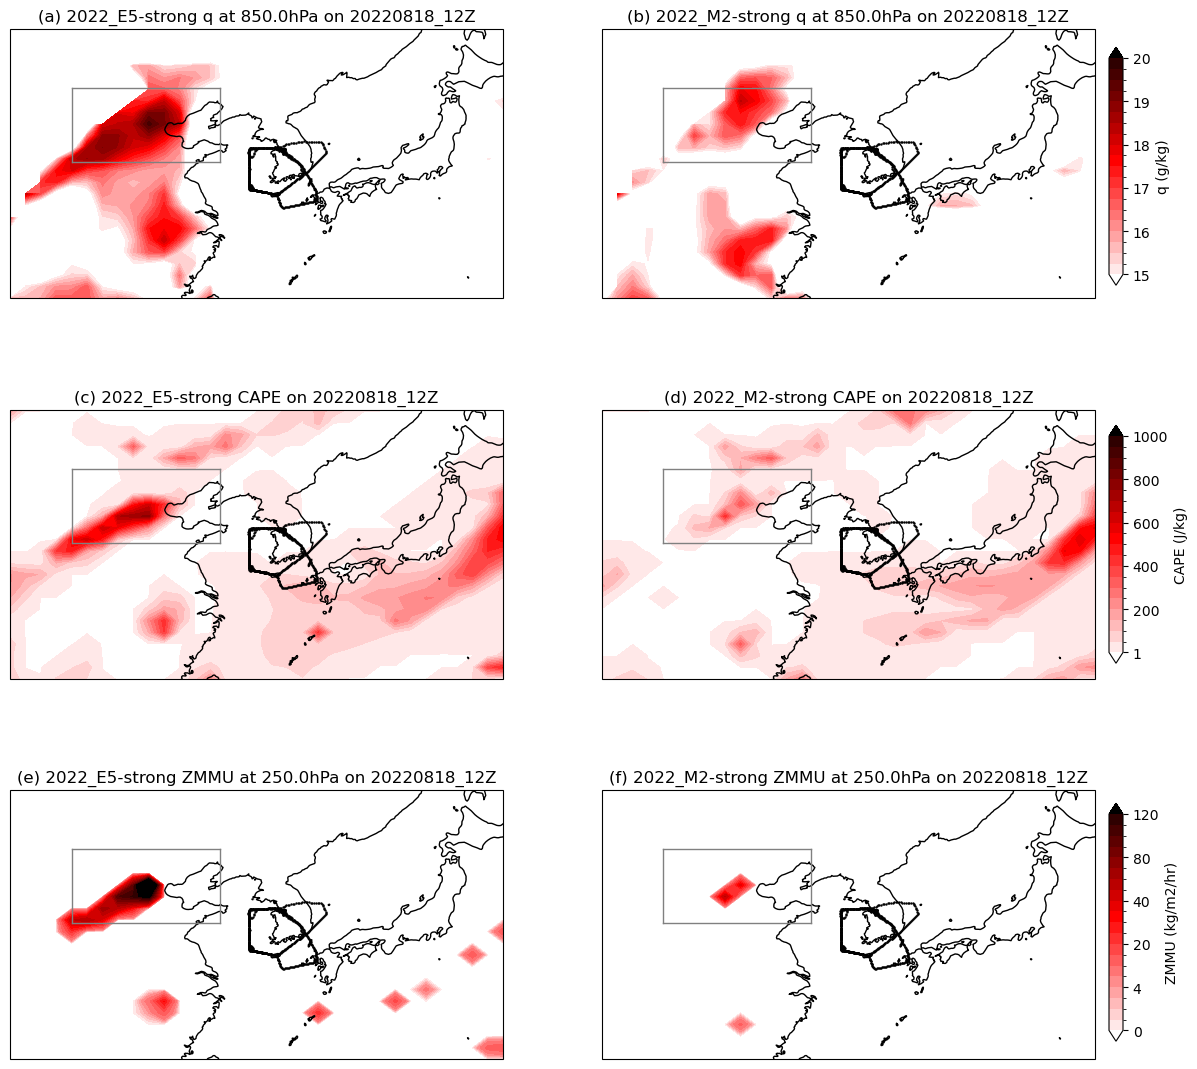

In [6]:

jd_arr = []
varmax_convdom0 = []
varmax_convdom1 = []
varmax_convdom2 = []
varmax_convdom3 = []

fig = plt.figure(figsize=(14,14))
ax0 = fig.add_subplot(3,2,1,projection=ccrs.PlateCarree())
ax1 = fig.add_subplot(3,2,2,projection=ccrs.PlateCarree())
ax2 = fig.add_subplot(3,2,3,projection=ccrs.PlateCarree())
ax3 = fig.add_subplot(3,2,4,projection=ccrs.PlateCarree())
ax4 = fig.add_subplot(3,2,5,projection=ccrs.PlateCarree())
ax5 = fig.add_subplot(3,2,6,projection=ccrs.PlateCarree())

simvar0_plot = interp_to_prslev(np.squeeze(simvar0), np.squeeze(simPS0), simlon, simlat, hyam, hybm, plot_levs[0])*pc.var_info[vars[0]]['mod']
simvar1_plot = interp_to_prslev(np.squeeze(simvar1), np.squeeze(simPS1), simlon, simlat, hyam, hybm, plot_levs[1])*pc.var_info[vars[1]]['mod']
simvar2_plot = interp_to_prslev(np.squeeze(simvar2), np.squeeze(simPS2), simlon, simlat, hyam, hybm, plot_levs[2])*pc.var_info[vars[2]]['mod']
simvar3_plot = interp_to_prslev(np.squeeze(simvar3), np.squeeze(simPS3), simlon, simlat, hyam, hybm, plot_levs[3])*pc.var_info[vars[3]]['mod']
simvar4_plot = interp_to_prslev(np.squeeze(simvar4), np.squeeze(simPS4), simlon, simlat, hyam, hybm, plot_levs[4])*pc.var_info[vars[4]]['mod']
simvar5_plot = interp_to_prslev(np.squeeze(simvar5), np.squeeze(simPS5), simlon, simlat, hyam, hybm, plot_levs[5])*pc.var_info[vars[5]]['mod']

cf0, varmax_lonind0, varmax_latind0, varmax0, cbar_lev0 = plot_map(ax0, simlon, simlat, simvar0_plot, vars[0], plot_levs[0], sims[0], extent, conv_dom, datestr0, cb=cb, let='(a) ')
cf1, varmax_lonind1, varmax_latind1, varmax1, cbar_lev1 = plot_map(ax1, simlon, simlat, simvar1_plot, vars[1], plot_levs[1], sims[1], extent, conv_dom, datestr1, cb=cb, let='(b) ')
cf2, varmax_lonind2, varmax_latind2, varmax2, cbar_lev2 = plot_map(ax2, simlon, simlat, simvar2_plot, vars[2], plot_levs[2], sims[2], extent, conv_dom, datestr2, cb=cb, let='(c) ')
cf3, varmax_lonind3, varmax_latind3, varmax3, cbar_lev3 = plot_map(ax3, simlon, simlat, simvar3_plot, vars[3], plot_levs[3], sims[3], extent, conv_dom, datestr3, cb=cb, let='(d) ')
cf4, varmax_lonind4, varmax_latind4, varmax4, cbar_lev4 = plot_map(ax4, simlon, simlat, simvar4_plot, vars[4], plot_levs[4], sims[4], extent, conv_dom, datestr4, cb=cb, let='(e) ')
cf5, varmax_lonind5, varmax_latind5, varmax5, cbar_lev5 = plot_map(ax5, simlon, simlat, simvar5_plot, vars[5], plot_levs[5], sims[5], extent, conv_dom, datestr5, cb=cb, let='(f) ')

varmax_convdom0.append(varmax0)
#varmax_convdom1.append(varmax1)
#varmax_convdom2.append(varmax2)
#varmax_convdom3.append(varmax3)

cbax0 = fig.add_axes([0.91,0.68,0.01,0.17])
cbar0 = plt.colorbar(cf0, cax = cbax0, orientation='vertical', ticks = cbar_lev0[::4], fraction=0.05)
cbar0.set_label(vars[0] + ' (' + pc.var_info[vars[0]]['unit'] + ')')

cbax2 = fig.add_axes([0.91,0.41,0.01,0.17])
cbar2 = plt.colorbar(cf2, cax = cbax2, orientation='vertical', ticks = cbar_lev2[::4], fraction=0.05)
cbar2.set_label(vars[2] + ' (' + pc.var_info[vars[2]]['unit'] + ')')

cbax4 = fig.add_axes([0.91,0.14,0.01,0.17])
cbar4 = plt.colorbar(cf4, cax = cbax4, orientation='vertical', ticks = cbar_lev4[::4], fraction=0.05)
cbar4.set_label(vars[4] + ' (' + pc.var_info[vars[4]]['unit'] + ')')

#plt.figtext(0.43,0.48,var_lab + ' at ' + str(plot_lev) + ' hPa on ' + datestr)

plt.savefig('/glade/u/home/wsmith/NudgeComparison_scripts/plots/Figure7.png')
plt.savefig('/glade/u/home/wsmith/NudgeComparison_scripts/plots/Figure7.pdf')
